# 12 · Recommender systems in the LLM era

Modern recommendation has two stages — **retrieval** (millions → hundreds) and **ranking** — and the LLM toolbox is now central to both:

1. **Sequential recommendation = next-token prediction over item ids.** SASRec (2018) is literally a decoder-only transformer whose vocabulary is the catalog; Meta's HSTU (2024) scales this idea to production. We reuse `TransformerLM` *unchanged*.
2. **Embedding retrieval**: users and items as vectors; the item embeddings learned by the sequential model carry collaborative signal, and **content embeddings** of item text solve cold start.
3. **LLM re-ranking and explanations** at the top of the funnel (tens of candidates).

**Evaluation:** leave-one-out, hit@k and nDCG@k against popularity and content baselines.

**Source:** `llmsuite/recsys.py`.

In [1]:
import os, sys, math, time, random, copy
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llmsuite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # climb from notebooks/<topic>/ up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llmsuite` works from any notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llmsuite.utils import seed_everything, get_device, count_params, human
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
from llmsuite.recsys import (make_catalog, make_interactions, leave_one_out_split, popularity_ranker, train_sasrec, sasrec_rank,
                             item_embeddings_from_model, content_embeddings, embedding_rank, llm_rerank, explain_recommendation)
from llmsuite.evaluation import evaluate_ranking
from llmsuite.llm_client import MockLLM

catalog = make_catalog(n_items=200, n_clusters=8, seed=0)
sessions = make_interactions(catalog, n_users=1500, min_len=8, max_len=25, stickiness=0.8, seed=0)
train_sessions, test = leave_one_out_split(sessions)
print(f"{catalog.n_items} items, {len(sessions)} users, avg session length {sum(map(len, sessions))/len(sessions):.1f}")
print("item 1:", catalog.titles[0], "—", catalog.descriptions[0])
print("a session (item ids):", sessions[0])

200 items, 1500 users, avg session length 16.7
item 1: Clever Secret 0 — A clever sci-fi secret about journey and voyage.
a session (item ids): [120, 85, 165, 134, 96, 48, 21, 80, 64, 192, 61, 5, 48]


## 1. Baselines
Always beat popularity first. Random hit@10 here is 10/200 = 5 %.

In [3]:
MAXLEN = 32
pop_rank = popularity_ranker(train_sessions, catalog.n_items)
def eval_ranker(rank_fn, name, k=10):
    queries = [(rank_fn(hist, k), {target}) for hist, target in test]
    m = evaluate_ranking(queries, ks=(1, 5, 10))
    print(f"{name:22s} hit@1 {m['hit@1']:.3f}  hit@5 {m['hit@5']:.3f}  hit@10 {m['hit@10']:.3f}  ndcg@10 {m['ndcg@10']:.3f}  mrr {m['mrr']:.3f}")
    return m

results = {}
results["random"] = eval_ranker(lambda h, k: random.sample([i for i in range(1, catalog.n_items + 1) if i not in h], k), "random")
results["popularity"] = eval_ranker(pop_rank, "popularity")
E_content = content_embeddings(catalog)
results["content (cold-start)"] = eval_ranker(lambda h, k: embedding_rank(E_content, h, k), "content embeddings")

random                 hit@1 0.004  hit@5 0.015  hit@10 0.032  ndcg@10 0.015  mrr 0.010
popularity             hit@1 0.020  hit@5 0.056  hit@10 0.097  ndcg@10 0.051  mrr 0.037
content embeddings     hit@1 0.002  hit@5 0.031  hit@10 0.059  ndcg@10 0.025  mrr 0.015


## 2. Sequential recommender = a language model over items
`vocab_size = n_items + 1` (0 = padding). Input: items `[:-1]`, target: items `[1:]`, padding ignored. That is all; the model, loss and optimizer are the ones from the pretraining notebook.

In [4]:
from llmsuite.model import ModelConfig, TransformerLM
seed_everything(0)
rec = TransformerLM(ModelConfig(vocab_size=catalog.n_items + 1, max_seq_len=MAXLEN + 1, d_model=64, n_layers=2, n_heads=4, n_kv_heads=2, dropout=0.1))
print(f"SASRec-style model: {human(rec.num_params())} params")
losses = train_sasrec(rec, train_sessions, max_len=MAXLEN, steps=600, batch_size=64, lr=2e-3, device=device, log_every=150)
results["SASRec (transformer)"] = eval_ranker(lambda h, k: sasrec_rank(rec, h, k, max_len=MAXLEN, device=device), "SASRec (transformer)")

SASRec-style model: 105.34K params


sasrec step    0  loss 5.259


sasrec step  150  loss 3.903


sasrec step  300  loss 3.778


sasrec step  450  loss 3.718


sasrec step  599  loss 3.446


SASRec (transformer)   hit@1 0.039  hit@5 0.137  hit@10 0.210  ndcg@10 0.114  mrr 0.084


## 3. Embedding retrieval from the learned model
The input embedding table of the sequential model is an item-vector space learned from co-occurrence (collaborative filtering). A user vector = recency-weighted mean of their items; retrieval = cosine top-k. This is the "two-tower-ish" retrieval stage you would serve from an ANN index.

In [5]:
E_collab = item_embeddings_from_model(rec)
results["collab embeddings"] = eval_ranker(lambda h, k: embedding_rank(E_collab, h, k), "collab embeddings")

# Look at an item's nearest neighbours in the learned space. Do they share its hidden taste cluster?
i = 5
sims = E_collab @ E_collab[i]; sims[0] = -1; sims[i] = -1
nn_items = np.argsort(-sims)[:5]
print(f"neighbours of '{catalog.titles[i-1]}' (cluster {catalog.item_cluster[i-1]}):")
for j in nn_items:
    print(f"   {catalog.titles[j-1]:28s} cluster {catalog.item_cluster[j-1]}  sim {sims[j]:.2f}")

collab embeddings      hit@1 0.039  hit@5 0.124  hit@10 0.207  ndcg@10 0.108  mrr 0.078
neighbours of 'Fast-Paced Heist 4' (cluster 4):
   Funny Voyage 12              cluster 4  sim 0.64
   Classic Rivalry 20           cluster 4  sim 0.50
   Dark Mystery 28              cluster 4  sim 0.49
   Emotional Voyage 36          cluster 4  sim 0.40
   Clever Journey 76            cluster 4  sim 0.40


## 4. LLM re-ranking and explanations
Retrieve 10 candidates with the sequential model, then let an LLM re-order them reading the user's history and item descriptions, and explain the top pick. Too slow for retrieval; valuable for the top of the funnel, for cold-start users (text only), and for explanations.

In [6]:
llm = MockLLM()           # use OpenAICompatibleClient(...) here for a real model
hist, target = test[0]
cands = sasrec_rank(rec, hist, 10, max_len=MAXLEN, device=device)
reranked = llm_rerank(llm, catalog, hist, cands)
print("history (last 3):", [catalog.titles[i-1] for i in hist[-3:]])
print("candidates      :", cands)
print("LLM re-ranked   :", reranked)
print("explanation     :", explain_recommendation(llm, catalog, hist, reranked[0]))

def two_stage(h, k):
    c = sasrec_rank(rec, h, 20, max_len=MAXLEN, device=device)
    return llm_rerank(llm, catalog, h, c)[:k]
sub_test = test[:150]                                      # the LLM calls are the slow part, so we evaluate on a subset
q = [(two_stage(h, 10), {t}) for h, t in sub_test]
q_base = [(sasrec_rank(rec, h, 10, max_len=MAXLEN, device=device), {t}) for h, t in sub_test]
print("\nsubset of 150 users — SASRec alone vs SASRec + LLM rerank:")
print("  SASRec        :", {k: round(v, 3) for k, v in evaluate_ranking(q_base, ks=(5, 10)).items()})
print("  + LLM rerank  :", {k: round(v, 3) for k, v in evaluate_ranking(q, ks=(5, 10)).items()})

history (last 3): ['Emotional Mystery 191', 'Emotional Journey 60', 'Fast-Paced Heist 4']
candidates      : [16, 8, 32, 24, 160, 168, 176, 109, 88, 128]
LLM re-ranked   : [160, 16, 8, 32, 176, 109, 128, 24, 168, 88]
explanation     : Because it shares the tone and themes of what they recently liked, Fast-Paced Voyage 159 is a natural next pick.



subset of 150 users — SASRec alone vs SASRec + LLM rerank:
  SASRec        : {'recall@5': 0.127, 'hit@5': 0.127, 'ndcg@5': 0.08, 'recall@10': 0.187, 'hit@10': 0.187, 'ndcg@10': 0.1, 'mrr': 0.073}
  + LLM rerank  : {'recall@5': 0.087, 'hit@5': 0.087, 'ndcg@5': 0.053, 'recall@10': 0.153, 'hit@10': 0.153, 'ndcg@10': 0.074, 'mrr': 0.05}


**Why does the re-ranker make things worse here?** The offline `MockLLM` re-ranks by word overlap between the candidate titles and the user's history — a much weaker signal than what SASRec learned from 1,500 users' sequences, so it shuffles good candidates down. That is a realistic lesson, not a bug: an LLM re-ranker is only worth its latency and cost if it beats the first stage **on your offline metrics**, and with a real model it typically helps on semantic or cold-start cases and can hurt on popular items. Swap in `OpenAICompatibleClient` and re-run this cell to measure it with a real LLM.

## 5. Evaluation summary

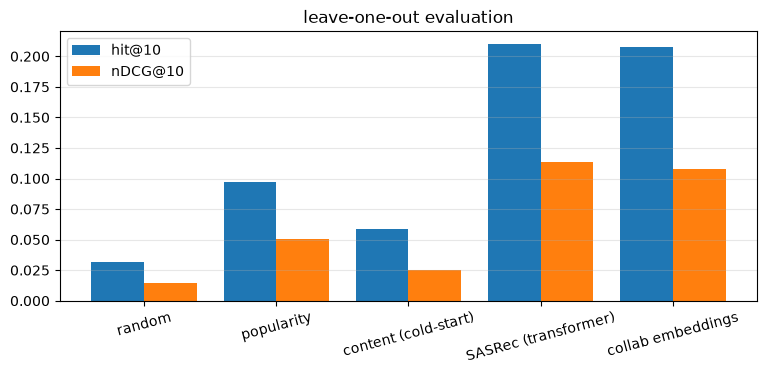

In [7]:
import matplotlib.pyplot as plt
names = list(results); h10 = [results[n]["hit@10"] for n in names]; nd = [results[n]["ndcg@10"] for n in names]
fig, ax = plt.subplots(figsize=(9, 3.5)); xs = np.arange(len(names))
ax.bar(xs - 0.2, h10, 0.4, label="hit@10"); ax.bar(xs + 0.2, nd, 0.4, label="nDCG@10")
ax.set_xticks(xs); ax.set_xticklabels(names, rotation=15); ax.legend(); ax.set_title("leave-one-out evaluation"); ax.grid(axis="y", alpha=.3); plt.show()

**Takeaways**
- The sequential transformer should clearly beat popularity and content baselines: it learns both taste clusters and within-cluster popularity from sequences alone.
- Content embeddings are weaker but work for items with **zero** interactions — in production you combine both (hybrid retrieval, exactly like RAG's dense + BM25).
- Offline metrics (hit@k, nDCG) are necessary but not sufficient: the real test is an **A/B experiment** on engagement/retention; offline-online gaps are common (popularity bias, feedback loops).
- Reading: SASRec (Kang & McAuley 2018), HSTU / "Actions speak louder than words" (Meta 2024), TIGER (semantic ids, Google 2023), LLM-Rec surveys.

**Next:** `13_modern_llm_applications.ipynb`.